# SpaGE tutorial

[SpaGE's tutorial](https://github.com/tabdelaal/SpaGE/blob/edd0fb7086eca791c6589020893eb4f034b195c7/SpaGE_Tutorial.ipynb) predicts unmeasured genes in **osmFISH** mouse somatosensory cortex from the
**AllenSSp** scRNA-seq data, written against
[`squidpy.experimental.tl.impute_spage`](https://github.com/scverse/squidpy/blob/main/src/squidpy/experimental/tl/_impute_spage.py).
Loading and normalization are upstream's, line for line; each `SpaGE(...)` call becomes one `impute_spage` call
with the same `n_pv=30` and upstream's hard-coded 50 neighbors and 0.3 cosine threshold, which are squidpy's defaults.

The datasets are the ones upstream points to, from [Zenodo](https://doi.org/10.5281/zenodo.3967291). The last
section runs upstream's `SpaGE()` from this repository's pinned copy on the same inputs.

In [1]:
import loompy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
from anndata import AnnData

import squidpy as sq

## Load and preprocess the AllenSSp dataset

Upstream's filtering and log-CPM normalization, then cells as rows.

In [2]:
RNA_data = pd.read_csv("SSp_exons_matrix.csv", header=0, index_col=0, sep=",")

# filter lowly expressed genes
Genes_count = np.sum(RNA_data > 0, axis=1)
RNA_data = RNA_data.loc[Genes_count >= 10, :]
del Genes_count


# Normalization
def Log_Norm_cpm(x):
    return np.log(((x / np.sum(x)) * 1000000) + 1)


RNA_data = RNA_data.apply(Log_Norm_cpm, axis=0)
adata_rna = AnnData(RNA_data.T)
adata_rna

AnnData object with n_obs × n_vars = 5613 × 30527
    layers: None (.X)

## Load and preprocess the osmFISH dataset

In [3]:
ds = loompy.connect("osmFISH_SScortex_mouse_all_cells.loom")
FISH_Genes = ds.ra["Gene"]
colAtr = ds.ca.keys()

df = pd.DataFrame()
for i in colAtr:
    df[i] = ds.ca[i]

osmFISH_meta = df.iloc[np.where(df.Valid == 1)[0], :]
osmFISH_data = ds[:, :]
osmFISH_data = osmFISH_data[:, np.where(df.Valid == 1)[0]]
osmFISH_data = pd.DataFrame(data=osmFISH_data, index=FISH_Genes)

del ds, colAtr, i, df, FISH_Genes

# Select cortical regions only to match the AllenSSp dataset
Cortex_Regions = ["Layer 2-3 lateral", "Layer 2-3 medial", "Layer 3-4", "Layer 4", "Layer 5", "Layer 6", "Pia Layer 1"]
Cortical = np.stack([i in Cortex_Regions for i in osmFISH_meta.Region])

osmFISH_meta = osmFISH_meta.iloc[Cortical, :]
osmFISH_data = osmFISH_data.iloc[:, Cortical]
del Cortex_Regions, Cortical

# Normalization
cell_count = np.sum(osmFISH_data, axis=0)


def Log_Norm_spatial(x):
    return np.log(((x / np.sum(x)) * np.median(cell_count)) + 1)


osmFISH_data = osmFISH_data.apply(Log_Norm_spatial, axis=0)
adata_fish = AnnData(osmFISH_data.T, obs=osmFISH_meta.set_index(osmFISH_data.columns.astype(str)))
adata_fish.obsm["spatial"] = adata_fish.obs[["X", "Y"]].to_numpy()
adata_fish

AnnData object with n_obs × n_vars = 3405 × 33
    obs: 'CellID', 'ClusterID', 'ClusterName', 'Region', 'Total_molecules', 'Valid', 'X', 'Y', '_tSNE_1', '_tSNE_2', 'size_pix', 'size_um2'
    obsm: 'spatial'
    layers: None (.X)

## Validate SpaGE using leave-one-gene-out cross validation

Each gene is dropped from the osmFISH data, predicted from the AllenSSp data, and compared with its measurement.

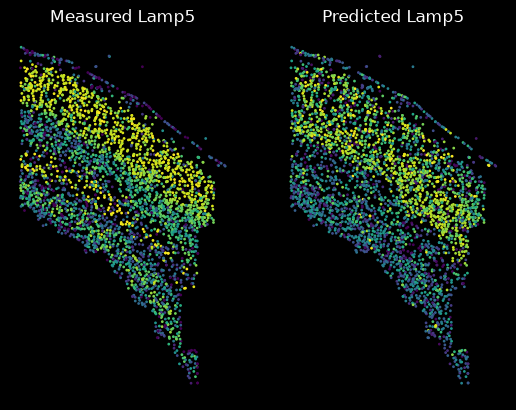

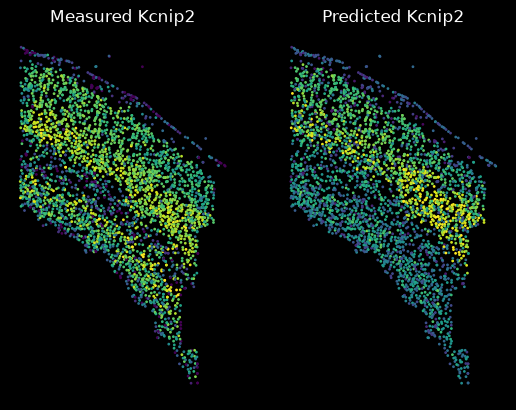

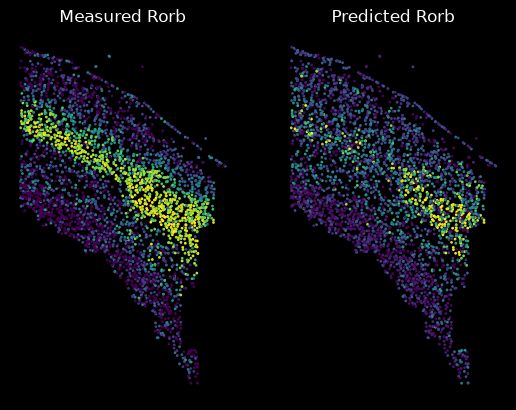

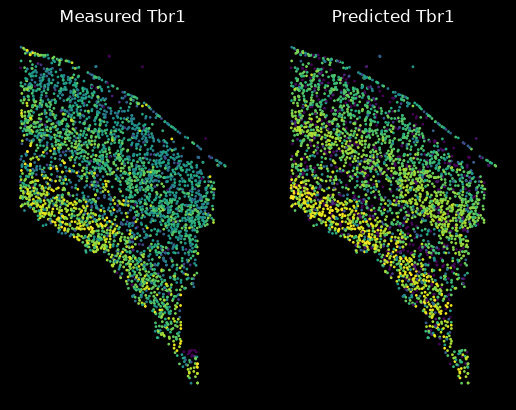

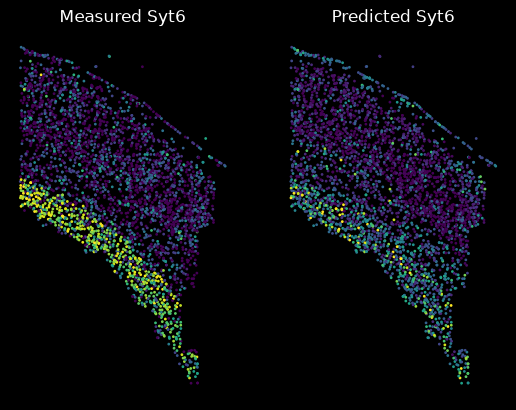

In [4]:
def plot_pair(left, right, titles):
    fig, axs = plt.subplots(1, 2)
    for ax, values, title in zip(axs, (left, right), titles, strict=True):
        values = np.minimum(values, np.percentile(values, 99))
        ax.axis("off")
        ax.scatter(adata_fish.obs["X"], adata_fish.obs["Y"], s=1, c=values)
        ax.set_title(title, fontsize=12)


Gene_set = ["Lamp5", "Kcnip2", "Rorb", "Tbr1", "Syt6"]
Correlations = pd.Series(index=Gene_set, dtype=float)
plt.style.use("dark_background")

for gene in Gene_set:
    imputed = sq.experimental.tl.impute_spage(
        adata_rna, adata_fish[:, adata_fish.var_names != gene], genes=[gene], n_pv=30, inplace=False
    )
    measured = adata_fish[:, gene].X.ravel()
    Correlations[gene] = st.spearmanr(measured, imputed[gene])[0]
    plot_pair(measured, imputed[gene].to_numpy(), [f"Measured {gene}", f"Predicted {gene}"])

## Correlation values between measured and predicted expressions

Beside the values upstream's tutorial printed. They agree to three decimals; the tutorial ran on 2020's
scikit-learn and numpy, and today's upstream gives the same values as squidpy (see the last section).

In [5]:
pd.DataFrame(
    {
        "squidpy": Correlations,
        "upstream tutorial": [0.412915, 0.419512, 0.497496, 0.543648, 0.379520],
    }
)

,squidpy,upstream tutorial
Lamp5,0.412915,0.412915
Kcnip2,0.419524,0.419512
Rorb,0.497792,0.497496
Tbr1,0.543572,0.543648
Syt6,0.380957,0.379520


## Prediction of new unmeasured spatial gene patterns

Ten genes osmFISH does not measure, each with a layer-specific pattern in the
[Allen ISH data](http://mouse.brain-map.org/).

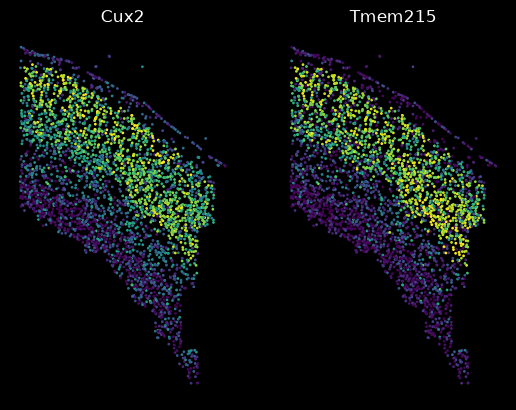

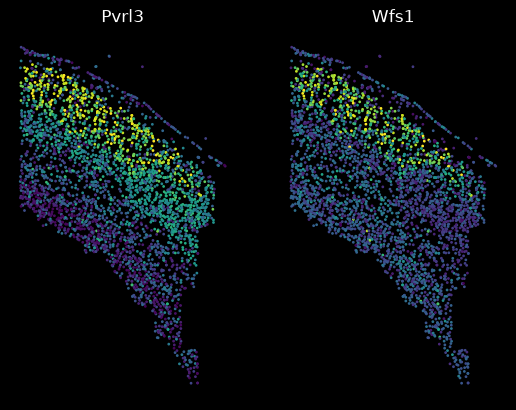

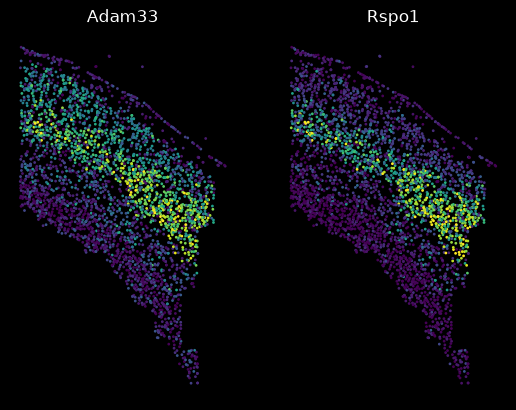

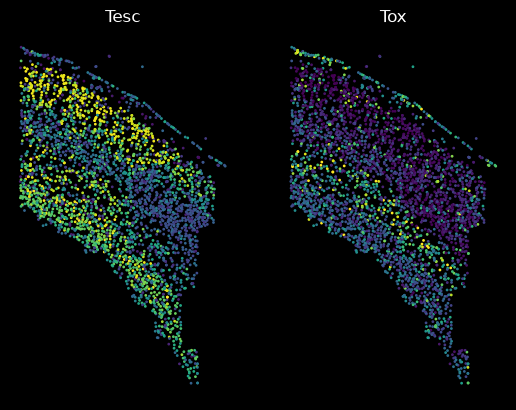

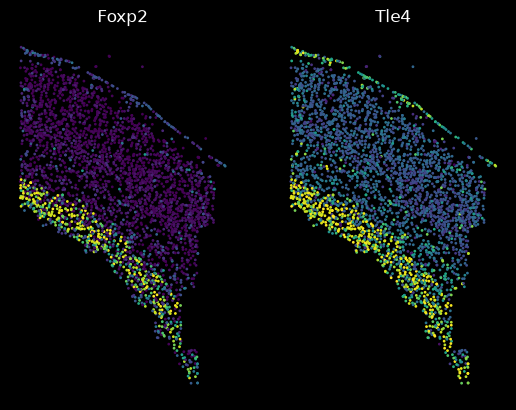

In [6]:
new_genes = ["Cux2", "Tmem215", "Pvrl3", "Wfs1", "Adam33", "Rspo1", "Tesc", "Tox", "Foxp2", "Tle4"]
sq.experimental.tl.impute_spage(adata_rna, adata_fish, genes=new_genes, n_pv=30, key_added="spage")
Imp_New_Genes = adata_fish.obsm["spage"]

for i in range(0, 10, 2):
    plot_pair(Imp_New_Genes[new_genes[i]].to_numpy(), Imp_New_Genes[new_genes[i + 1]].to_numpy(), new_genes[i : i + 2])

## Against upstream

Upstream's `SpaGE()` from this repository's pinned copy (`vendor/SpaGE`), on the DataFrames the sections above
built.

In [7]:
from squidpy_ports.spage import upstream

upstream_new = upstream.load().SpaGE(osmFISH_data.T, RNA_data.T, n_pv=30, genes_to_predict=new_genes)
difference = np.abs(Imp_New_Genes[new_genes].to_numpy() - upstream_new[new_genes].to_numpy())
print(f"max |squidpy - upstream| = {difference.max():.2e}, largest value = {upstream_new.to_numpy().max():.2f}")
print(f"cells differing by more than 1e-8: {int((difference.max(axis=1) > 1e-8).sum())} of {len(difference)}")

max |squidpy - upstream| = 4.44e-15, largest value = 5.89
cells differing by more than 1e-8: 0 of 3405
